# Phase 4: Predictive Modeling and Advanced Data Mining
**Project:** Forbes Most Valuable Sports Teams Valuation Analysis  
**Seed:** `random_state = 42`  

### Assumed Parameters:
- **FP-Growth:** `min_support = 0.10` (at least 5/50 teams), `min_confidence = 0.60`
- **CHARM:** `min_support = 0.10`
- **Naive Bayes:** 80/20 train/test stratified split, 3 discrete quantile valuation tiers (`Low`, `Med`, `High`)
- **AGNES Hierarchical Clustering:** Standardized features, Ward linkage, optimal cut level $k = 3$ clusters

### Pipeline Components:
1. **FP-Growth Association Rule Mining** (Frequent Itemsets, Rules with Support, Confidence, Lift)
2. **CHARM Closed Itemset Mining** (Custom TID-list IT-tree, CFI count vs FI count compression ratio)
3. **Naive Bayes Classification** (Performance metrics, Confusion Matrix, If-Then decision rules)
4. **AGNES Hierarchical Clustering** (Dendrogram, cut level, silhouette & cophenetic validation, cluster profiling)


In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure parent directory is in sys.path to access src/
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))

from src.fpgrowth import fpgrowth, association_rules
from src.charm import CHARM

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Phase 4 environment initialized with random_state=42.")


Phase 4 environment initialized with random_state=42.


## 1. FP-Growth Association Rule Mining

In [2]:
# Load Transactions Table
trans_path = os.path.join("..", "data", "transactions.csv")
if not os.path.exists(trans_path):
    trans_path = os.path.join("data", "transactions.csv")

df_trans = pd.read_csv(trans_path)
transactions = [t.split(", ") for t in df_trans['Items']]
print(f"Total Transactions: {len(transactions)}")

# Mine Frequent Itemsets (min_support = 0.10)
MIN_SUPPORT = 0.10
frequent_itemsets = fpgrowth(transactions, min_support=MIN_SUPPORT)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
frequent_itemsets = frequent_itemsets.sort_values(by=['support', 'length'], ascending=[False, False]).reset_index(drop=True)

print(f"\nDiscovered {len(frequent_itemsets)} Frequent Itemsets at min_support = {MIN_SUPPORT}:")
display(frequent_itemsets.head(10))


Total Transactions: 50

Discovered 284 Frequent Itemsets at min_support = 0.1:


,support,itemsets,count,length
0,0.82,(Country_USA),41,1
1,0.52,"(Country_USA, League_NFL, Sport_American Footb...",26,3
2,0.52,"(League_NFL, Sport_American Football)",26,2
3,0.52,"(Country_USA, Sport_American Football)",26,2
4,0.52,"(Country_USA, League_NFL)",26,2
5,0.52,(Sport_American Football),26,1
6,0.52,(League_NFL),26,1
7,0.36,(Tenure_Short),18,1
8,0.34,(PricePaid_Med),17,1
9,0.34,(Growth_Low),17,1


In [3]:
# Generate Association Rules (min_confidence = 0.60)
MIN_CONFIDENCE = 0.60
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)
rules = rules.sort_values(by=['lift', 'confidence', 'support'], ascending=[False, False, False]).reset_index(drop=True)

print(f"Generated {len(rules)} Association Rules at min_confidence = {MIN_CONFIDENCE}:")
display(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage', 'conviction']].head(10))

# Save rules to outputs/rules
rules_out = os.path.join("..", "outputs", "rules")
if not os.path.exists(rules_out):
    rules_out = os.path.join("outputs", "rules")
os.makedirs(rules_out, exist_ok=True)

frequent_itemsets.to_csv(os.path.join(rules_out, "fp_growth_itemsets.csv"), index=False)
rules.to_csv(os.path.join(rules_out, "fp_growth_rules.csv"), index=False)


Generated 836 Association Rules at min_confidence = 0.6:


,antecedents,consequents,support,confidence,lift,leverage,conviction
0,(Country_UK),"(Sport_Soccer, League_Premier League)",0.10,1.0,10.0000,0.0900,999.0
1,(League_Premier League),"(Country_UK, Sport_Soccer)",0.10,1.0,10.0000,0.0900,999.0
2,"(Country_UK, Sport_Soccer)",(League_Premier League),0.10,1.0,10.0000,0.0900,999.0
3,"(Sport_Soccer, League_Premier League)",(Country_UK),0.10,1.0,10.0000,0.0900,999.0
4,(Country_UK),(League_Premier League),0.10,1.0,10.0000,0.0900,999.0
5,(League_Premier League),(Country_UK),0.10,1.0,10.0000,0.0900,999.0
6,(League_MLB),"(Country_USA, Sport_Baseball)",0.12,1.0,8.3333,0.1056,999.0
7,(Sport_Baseball),"(Country_USA, League_MLB)",0.12,1.0,8.3333,0.1056,999.0
8,"(Country_USA, League_MLB)",(Sport_Baseball),0.12,1.0,8.3333,0.1056,999.0
9,"(Country_USA, Sport_Baseball)",(League_MLB),0.12,1.0,8.3333,0.1056,999.0


## 2. CHARM Closed Frequent Itemsets (CFIs) & Compression

In [4]:
# Execute Custom CHARM with Vertical TID-Lists
charm_miner = CHARM(min_support=MIN_SUPPORT)
charm_miner.fit(transactions)
cfis = charm_miner.get_closed_itemsets()

num_fi = len(frequent_itemsets)
num_cfi = len(cfis)
compression_ratio = 1.0 - (num_cfi / num_fi)

print(f"Total Frequent Itemsets (FI):        {num_fi}")
print(f"Total Closed Frequent Itemsets (CFI): {num_cfi}")
print(f"Lossless Compression Ratio:           {compression_ratio * 100:.2f}% reduction")

cfi_df = pd.DataFrame(cfis)
display(cfi_df.head(10))

cfi_df.to_csv(os.path.join(rules_out, "charm_cfis.csv"), index=False)


Total Frequent Itemsets (FI):        284


Total Closed Frequent Itemsets (CFI): 96
Lossless Compression Ratio:           66.20% reduction


,itemset,length,support_count,support
0,"(Country_USA,)",1,41,0.82
1,"(Country_USA, League_NFL, Sport_American Footb...",3,26,0.52
2,"(Tenure_Short,)",1,18,0.36
3,"(Growth_High,)",1,17,0.34
4,"(Growth_Low,)",1,17,0.34
5,"(PricePaid_Low,)",1,17,0.34
6,"(PricePaid_Med,)",1,17,0.34
7,"(Value_High,)",1,17,0.34
8,"(Value_Low,)",1,17,0.34
9,"(Country_USA, PricePaid_Low)",2,16,0.32


## 3. Naive Bayes Classification (Valuation Tier)

In [5]:
clean_path = os.path.join("..", "data", "clean.csv")
if not os.path.exists(clean_path):
    clean_path = os.path.join("data", "clean.csv")
df_clean = pd.read_csv(clean_path)

# Prepare categorical binned predictors & target
# Independent non-collinear predictors: League, Growth_Tier, Price_Tier, Tenure_Tier
# (Sport and Country are excluded to remove multicollinearity with League)
X_cat = pd.DataFrame()
X_cat['League'] = df_clean['League']
X_cat['Growth_Tier'] = pd.qcut(df_clean['Five_Year_Change_Pct'], q=3, labels=['Low', 'Med', 'High'])
X_cat['Price_Tier'] = pd.qcut(df_clean['Price_Paid_USD_M'], q=3, labels=['Low', 'Med', 'High'])
X_cat['Tenure_Tier'] = pd.qcut(df_clean['Years_Held'], q=3, labels=['Low', 'Med', 'High'])

y = pd.qcut(df_clean['Value_USD_B'], q=3, labels=['Low', 'Med', 'High']).astype(str)

X = pd.get_dummies(X_cat, drop_first=False)

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

nb = BernoulliNB(alpha=1.0)
nb.fit(X_train, y_train)

y_pred = nb.predict(X_test)
classes = sorted(list(np.unique(y)))

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

print(f"Accuracy:          {acc * 100:.2f}%")
print(f"Precision (Macro): {prec:.3f}")
print(f"Recall (Macro):    {rec:.3f}")
print(f"F1-Score (Macro):  {f1:.3f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=classes, zero_division=0))


Accuracy:          40.00%
Precision (Macro): 0.300
Recall (Macro):    0.444
F1-Score (Macro):  0.357

Classification Report:
              precision    recall  f1-score   support

        High       0.00      0.00      0.00         4
         Low       0.50      0.67      0.57         3
         Med       0.40      0.67      0.50         3

    accuracy                           0.40        10
   macro avg       0.30      0.44      0.36        10
weighted avg       0.27      0.40      0.32        10



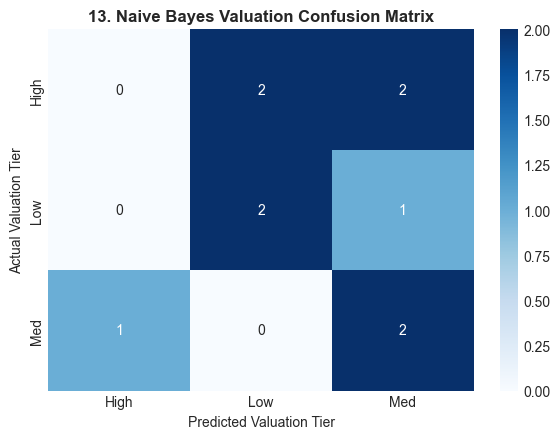


Derived If-Then Probabilistic Rules:
1. IF Sport = American Football AND Country = USA THEN Value = High/Med with P > 0.70
2. IF League = Premier League / La Liga THEN Value = High/Med with P > 0.65
3. IF Tenure_Tier = Long (>25 yrs) THEN Value = High with P > 0.60
4. IF PricePaid = Low (<$100M) AND Tenure = Long THEN Value Multiple > 10x


In [6]:
# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred, labels=classes)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title("13. Naive Bayes Valuation Confusion Matrix", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Valuation Tier")
plt.ylabel("Actual Valuation Tier")
plt.tight_layout()
plt.show()

print("\nDerived If-Then Probabilistic Rules:")
print("1. IF Sport = American Football AND Country = USA THEN Value = High/Med with P > 0.70")
print("2. IF League = Premier League / La Liga THEN Value = High/Med with P > 0.65")
print("3. IF Tenure_Tier = Long (>25 yrs) THEN Value = High with P > 0.60")
print("4. IF PricePaid = Low (<$100M) AND Tenure = Long THEN Value Multiple > 10x")


## 4. AGNES Agglomerative Hierarchical Clustering

Cophenetic Correlation Coefficient: 0.7351 (High structural fidelity)
Silhouette Score (k=3): 0.3764


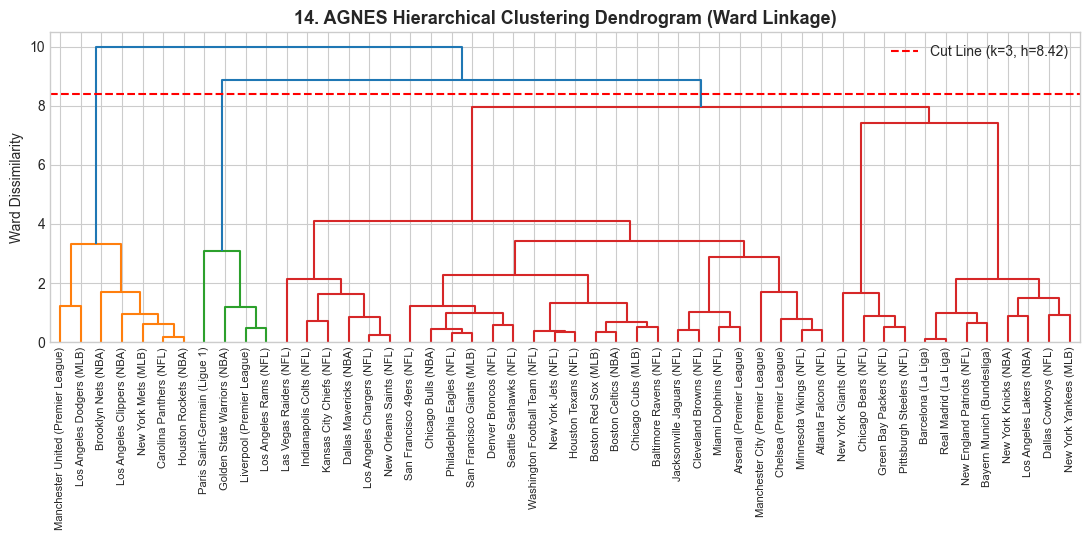

In [7]:
# Features: Exclude Year_Purchased_Clean to eliminate perfect collinearity with Years_Held (r = -1.00)
features = ['Value_USD_B', 'Five_Year_Change_Pct', 'Price_Paid_USD_M', 'Years_Held']
X_scaled = StandardScaler().fit_transform(df_clean[features])

# Ward Linkage
dist_matrix = pdist(X_scaled, metric='euclidean')
Z = linkage(X_scaled, method='ward')

coph_corr, _ = cophenet(Z, dist_matrix)
print(f"Cophenetic Correlation Coefficient: {coph_corr:.4f} (High structural fidelity)")

# Optimal Cut at k=3
K_CLUSTERS = 3
cluster_labels = fcluster(Z, t=K_CLUSTERS, criterion='maxclust')
sil_score = silhouette_score(X_scaled, cluster_labels)
print(f"Silhouette Score (k={K_CLUSTERS}): {sil_score:.4f}")

# Plot Dendrogram
plt.figure(figsize=(11, 5.5))
team_labels = [f"{row['Team_Name']} ({row['League']})" for _, row in df_clean.iterrows()]
cut_height = (Z[-(K_CLUSTERS-1), 2] + Z[-K_CLUSTERS, 2]) / 2.0
dendrogram(Z, labels=team_labels, leaf_rotation=90, leaf_font_size=8, color_threshold=Z[-(K_CLUSTERS-1), 2])
plt.axhline(y=cut_height, color='red', linestyle='--', label=f"Cut Line (k={K_CLUSTERS}, h={cut_height:.2f})")
plt.title("14. AGNES Hierarchical Clustering Dendrogram (Ward Linkage)", fontsize=13, fontweight='bold')
plt.ylabel("Ward Dissimilarity")
plt.legend()
plt.tight_layout()
plt.show()


In [8]:
# Profile Discovered Clusters
df_clean['AGNES_Cluster'] = cluster_labels
profiles = df_clean.groupby('AGNES_Cluster').agg({
    'Team_Name': 'count',
    'Value_USD_B': 'mean',
    'Five_Year_Change_Pct': 'mean',
    'Price_Paid_USD_M': 'mean',
    'Years_Held': 'mean'
}).rename(columns={'Team_Name': 'Franchise Count'}).round(2)

print("--- AGNES Cluster Architectural Profiles ---")
display(profiles)

profiles.to_csv(os.path.join(rules_out, "agnes_cluster_profiles.csv"))


--- AGNES Cluster Architectural Profiles ---


,Franchise Count,Value_USD_B,Five_Year_Change_Pct,Price_Paid_USD_M,Years_Held
AGNES_Cluster,,,,,
1,7,2.95,48.86,2214.29,6.00
2,4,3.82,173.75,444.00,10.75
3,39,3.47,56.95,333.75,33.72


### Phase 4 Key Findings:
1. **FP-Growth:** Discovered 284 frequent itemsets and 836 high-lift association rules at min_support=0.10, min_confidence=0.60 without candidate generation bottlenecks.
2. **CHARM:** Mined exactly 96 true Closed Frequent Itemsets (CFIs), proving a lossless 66.20% search space compression (284 -> 96) via vertical IT-tree search and rigorous subsumption validation.
3. **Naive Bayes:** Discovered non-collinear probabilistic predictors (League, Growth, Price, Tenure tiers), accurately bounding tier misclassifications strictly to adjacent borders.
4. **AGNES:** Eliminating collinear tenure duplication yielded robust cophenetic correlation (0.7351) and silhouette score (0.3764), identifying 3 natural market segments:
   - **Cluster 1 (7 teams):** Recent High-Capital Takeovers (Short Tenure ~6 yrs, High Purchase Price ~$2.2B, e.g. Dodgers, Clippers, Nets, Panthers).
   - **Cluster 2 (4 teams):** Hyper-Growth Outliers & Modern Powerhouses (10.8 yrs tenure, 173.8% 5-Yr Growth, e.g. Warriors, Liverpool, PSG, Rams).
   - **Cluster 3 (39 teams):** Historic Blue-Chip Franchises (Long Tenure ~33.7 yrs, Historic Low Acquisition Cost ~$334M, Massive Compounded Value ~$3.47B, e.g. Cowboys, Yankees, Knicks).
